In [ ]:
#Install dependencies
!pip install segmentation-models-pytorch
!pip install albumentations
!pip install opencv-python
!pip install torchmetrics
from torch.utils.data import DataLoader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 1.9 MB/s eta 0:00:00


In [ ]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.3/260.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 42.6 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92


In [ ]:
#Download Dataset
import os
from roboflow import Roboflow

# ==== Configuration ====
# Roboflow API key — never hardcode this.
# In Colab: store it once via the "Secrets" tab (key icon in left sidebar),
# name it ROBOFLOW_API_KEY, and enable notebook access.
from google.colab import userdata
ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("maulis-workspace-l7bbl").project("fruit_detection-rdzge")
dataset = project.version(1).download("coco-segmentation")


DATASET_BASE_PATH = "/content/Fruit_detection-1"   # same Roboflow export as Phase 2, re-exported in COCO format
TRAIN_IMAGES_DIR = f"{DATASET_BASE_PATH}/train"
TRAIN_ANNOTATIONS = f"{TRAIN_IMAGES_DIR}/_annotations.coco.json"
VAL_IMAGES_DIR = f"{DATASET_BASE_PATH}/valid"
VAL_ANNOTATIONS = f"{VAL_IMAGES_DIR}/_annotations.coco.json"
TEST_IMAGES_DIR = f"{DATASET_BASE_PATH}/test"
TEST_ANNOTATIONS = f"{TEST_IMAGES_DIR}/_annotations.coco.json"

MODEL_SAVE_DIR = "./saved_models"

SAMPLE_IMAGE_PATH = "ADD PATH TO YOUR SAMPLE IMAGE"    # multi-fruit image for qualitative demo

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Fruit_detection-1 in coco-segmentation:: 100%|██████████| 1004/1004 [00:00<00:00, 5110.99it/s]


In [ ]:
#Augmentation
from pycocotools.coco import COCO
from torch.utils.data import Dataset
import os
import cv2
import numpy as np
import torch

class FruitSegDataset(Dataset):

    def __init__(self,image_dir,ann_file):
        self.coco = COCO(ann_file)

        self.ids = list(self.coco.imgs.keys())

        self.image_dir = image_dir

    def __len__(self):
        return len(self.ids)

    def __getitem__(self,idx):

        img_id = self.ids[idx]

        img_info = self.coco.loadImgs(img_id)[0]

        path = os.path.join(
            self.image_dir,
            img_info['file_name']
        )

        image = cv2.imread(path)
        image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

        anns = self.coco.loadAnns(
            self.coco.getAnnIds(imgIds=img_id)
        )

        mask = np.zeros(
            (img_info['height'],
             img_info['width']),
             dtype=np.uint8
        )

        for ann in anns:
            mask |= self.coco.annToMask(ann)

        image = cv2.resize(image,(256,256))
        mask = cv2.resize(mask,(256,256))

        image = image/255.0

        image = torch.tensor(
            image,
            dtype=torch.float32
        ).permute(2,0,1)

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0)

        return image, mask

In [ ]:
from torch.utils.data import DataLoader

train_dataset = FruitSegDataset(
    TRAIN_IMAGES_DIR,
    TRAIN_ANNOTATIONS
)

val_dataset = FruitSegDataset(
    VAL_IMAGES_DIR,
    VAL_ANNOTATIONS
)


train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8
)

loading annotations into memory...
Done (t=0.26s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


In [ ]:
import segmentation_models_pytorch as smp

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

In [ ]:
#Run using T4-GPU
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = model.to(device)

In [ ]:
dice_loss = smp.losses.DiceLoss(
    mode="binary"
)

bce_loss = torch.nn.BCEWithLogitsLoss()

In [ ]:
def loss_fn(pred,mask):

    return (
        dice_loss(pred,mask)
        +
        bce_loss(pred,mask)
    )

In [ ]:
import torch.optim as optim

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [ ]:
import torch

# Define dice_score function locally for this cell
def dice_score(pred, mask):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()
    inter = (pred * mask).sum()
    union = pred.sum() + mask.sum()
    return (2 * inter + 1e-4) / (union + 1e-4)

# Define iou_score function locally for this cell
def iou_score(pred, mask):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()
    inter = (pred * mask).sum() # Intersection
    union = (pred.sum() + mask.sum() - inter) # Union
    return ((inter + 1e-4) / (union + 1e-4)) # Corrected: numerator should be just 'inter'

# Define pixel_accuracy function
def pixel_accuracy(pred, mask):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()
    correct_pixels = (pred == mask).sum().float()
    total_pixels = mask.numel()
    return correct_pixels / total_pixels

In [ ]:
import torchmetrics
from tqdm import tqdm
import torch

epochs = 10

# Initialize lists to store metrics per epoch
train_losses = []
val_losses = []
val_ious = []
val_dices = []
val_precisions = []
val_recalls = []
val_accuracies = [] # New list for validation accuracy

# Define additional metrics for validation using torchmetrics
binary_precision = torchmetrics.classification.BinaryPrecision().to(device)
binary_recall = torchmetrics.classification.BinaryRecall().to(device)

for epoch in range(epochs):
    model.train()
    current_train_loss = 0

    # Wrap train_loader with tqdm for a progress bar
    for images,masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} Training"):
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, masks)
        loss.backward()
        optimizer.step()
        current_train_loss += loss.item()

    avg_train_loss = current_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    print(f"Epoch {epoch+1} Training Loss: {avg_train_loss:.4f}")


    # Validation Phase
    model.eval()
    current_val_loss = 0
    current_val_iou = 0
    current_val_dice = 0
    current_val_accuracy = 0

    # Reset torchmetrics for validation
    binary_precision.reset()
    binary_recall.reset()

    with torch.no_grad():
        for images,masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} Validation"):
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, masks)
            current_val_loss += loss.item()

            # Calculate IoU, Dice, and Pixel Accuracy for the batch
            current_val_iou += iou_score(outputs, masks).item()
            current_val_dice += dice_score(outputs, masks).item()
            current_val_accuracy += pixel_accuracy(outputs, masks).item()

            # For precision and recall, apply sigmoid and threshold
            preds_binary = (torch.sigmoid(outputs))
            binary_precision.update(preds_binary, masks.int())
            binary_recall.update(preds_binary, masks.int())

    avg_val_loss = current_val_loss / len(val_loader)
    avg_val_iou = current_val_iou / len(val_loader)
    avg_val_dice = current_val_dice / len(val_loader)
    avg_val_accuracy = current_val_accuracy / len(val_loader)
    avg_val_precision = binary_precision.compute().item()
    avg_val_recall = binary_recall.compute().item()

    val_losses.append(avg_val_loss)
    val_ious.append(avg_val_iou)
    val_dices.append(avg_val_dice)
    val_precisions.append(avg_val_precision)
    val_recalls.append(avg_val_recall)
    val_accuracies.append(avg_val_accuracy)

    print(f"Epoch {epoch+1}/{epochs} Val Loss: {avg_val_loss:.4f}, Val IoU: {avg_val_iou:.4f}, Val Dice: {avg_val_dice:.4f}, Val Precision: {avg_val_precision:.4f}, Val Recall: {avg_val_recall:.4f}, Val Accuracy: {avg_val_accuracy:.4f}")

print("Training complete!")

Epoch 1/10 Training: 100%|██████████| 104/104 [00:24<00:00,  4.21it/s]


Epoch 1 Training Loss: 0.3435


Epoch 1/10 Validation: 100%|██████████| 16/16 [00:01<00:00, 11.74it/s]


Epoch 1/10 Val Loss: 0.5093, Val IoU: 0.6639, Val Dice: 0.7946, Val Precision: 0.7270, Val Recall: 0.8842, Val Accuracy: 0.9488


Epoch 2/10 Training: 100%|██████████| 104/104 [00:25<00:00,  4.11it/s]


Epoch 2 Training Loss: 0.2778


... (30 outputs left out)

Epoch 10/10 Training: 100%|██████████| 104/104 [00:24<00:00,  4.25it/s]


Epoch 10 Training Loss: 0.1218


Epoch 10/10 Validation: 100%|██████████| 16/16 [00:01<00:00, 12.04it/s]

Epoch 10/10 Val Loss: 0.3374, Val IoU: 0.7308, Val Dice: 0.8402, Val Precision: 0.8648, Val Recall: 0.8169, Val Accuracy: 0.9644
Training complete!


## Training and Validation Metrics Plots

In [ ]:
import matplotlib.pyplot as plt

# Plot Training and Validation Loss
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), train_losses, label='Training Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Validation Loss')
plt.title('Training and Validation Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('training_validation_loss.png')
plt.close()

In [ ]:
# Plot Validation IoU and Dice Score
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), val_ious, label='Validation IoU', marker='o')
plt.plot(range(1, epochs + 1), val_dices, label='Validation Dice Score', marker='x')
plt.title('Validation IoU and Dice Score per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.savefig('validation_iou_dice.png')
plt.close()

In [ ]:
# Plot Validation Precision and Recall
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), val_precisions, label='Validation Precision', marker='o')
plt.plot(range(1, epochs + 1), val_recalls, label='Validation Recall', marker='x')
plt.title('Validation Precision and Recall per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.savefig('validation_precision_recall.png')
plt.close()

## Inference Time and FPS Calculation (Re-attempt)

In [ ]:
import time

model.eval()
num_inference_images = 100 # Number of images to use for inference time calculation
total_inference_time = 0

with torch.no_grad():
    for i in range(num_inference_images):
        # Get a random image from the validation dataset
        image, _ = val_dataset[i % len(val_dataset)]
        image = image.unsqueeze(0).to(device) # Add batch dimension and move to device

        start_time = time.time()
        _ = model(image)
        end_time = time.time()

        total_inference_time += (end_time - start_time)

avg_inference_time = total_inference_time / num_inference_images
fps = 1 / avg_inference_time

print(f"Average Inference Time per image: {avg_inference_time:.4f} seconds")
print(f"Frames Per Second (FPS): {fps:.2f}")

Average Inference Time per image: 0.0074 seconds
Frames Per Second (FPS): 135.19


## Combined Metrics Graphs

In [ ]:
import matplotlib.pyplot as plt

# Create a figure with 3 subplots (3 rows, 1 column)
fig, axes = plt.subplots(3, 1, figsize=(10, 15)) # Adjust figsize as needed for clarity

# Plot 1: Training and Validation Loss
axes[0].plot(range(1, epochs + 1), train_losses, label='Training Loss')
axes[0].plot(range(1, epochs + 1), val_losses, label='Validation Loss')
axes[0].set_title('Training and Validation Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Plot 2: Validation IoU and Dice Score
axes[1].plot(range(1, epochs + 1), val_ious, label='Validation IoU', marker='o')
axes[1].plot(range(1, epochs + 1), val_dices, label='Validation Dice Score', marker='x')
axes[1].set_title('Validation IoU and Dice Score per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(True)

# Plot 3: Validation Precision and Recall
axes[2].plot(range(1, epochs + 1), val_precisions, label='Validation Precision', marker='o')
axes[2].plot(range(1, epochs + 1), val_recalls, label='Validation Recall', marker='x')
axes[2].set_title('Validation Precision and Recall per Epoch')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Score')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.savefig('/content/phase 3 graphs.png')
plt.close(fig) # Close the figure to free up memory
print(f"Combined metrics plot saved to /content/phase 3 graphs.png")

Combined metrics plot saved to /content/phase 3 graphs.png


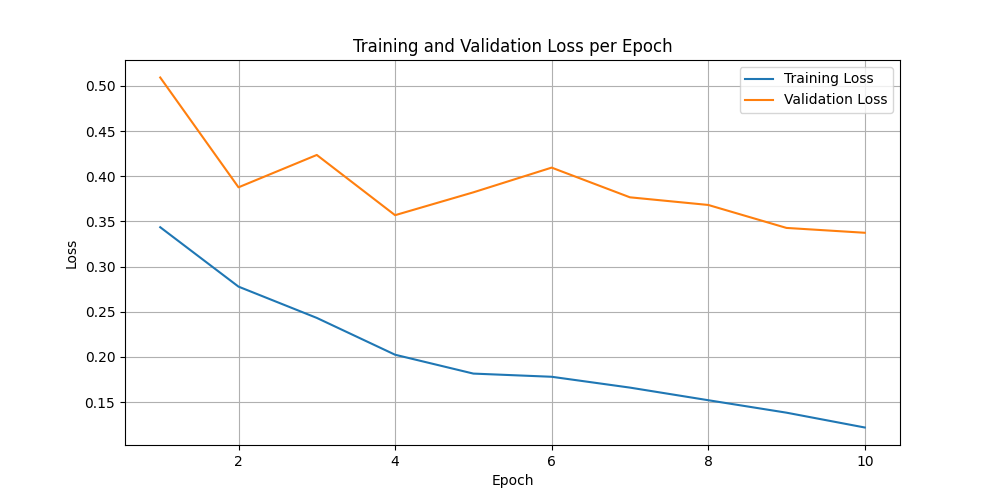

In [ ]:
from IPython.display import Image
Image('training_validation_loss.png')

### Validation IoU and Dice Score

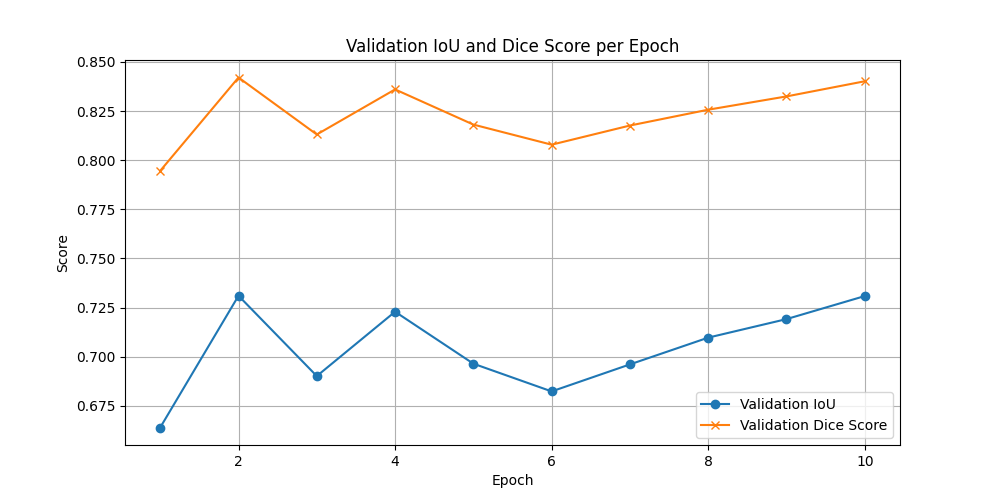

In [ ]:
from IPython.display import Image
Image('validation_iou_dice.png')

### Validation Precision and Recall

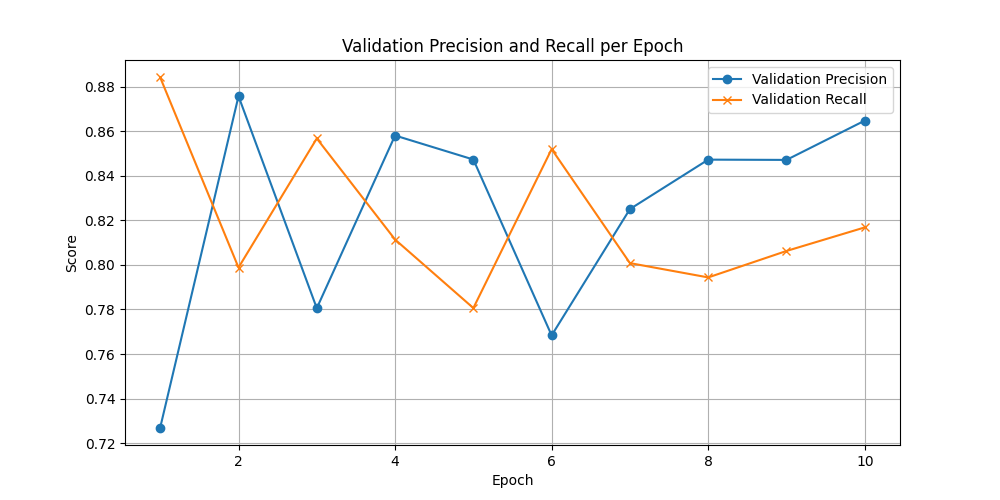

In [ ]:
from IPython.display import Image
Image('validation_precision_recall.png')

### Validation Accuracy

In [ ]:
# Plot Validation Accuracy
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), val_accuracies, label='Validation Accuracy', marker='s', color='purple')
plt.title('Validation Pixel Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('validation_accuracy.png')
plt.close()

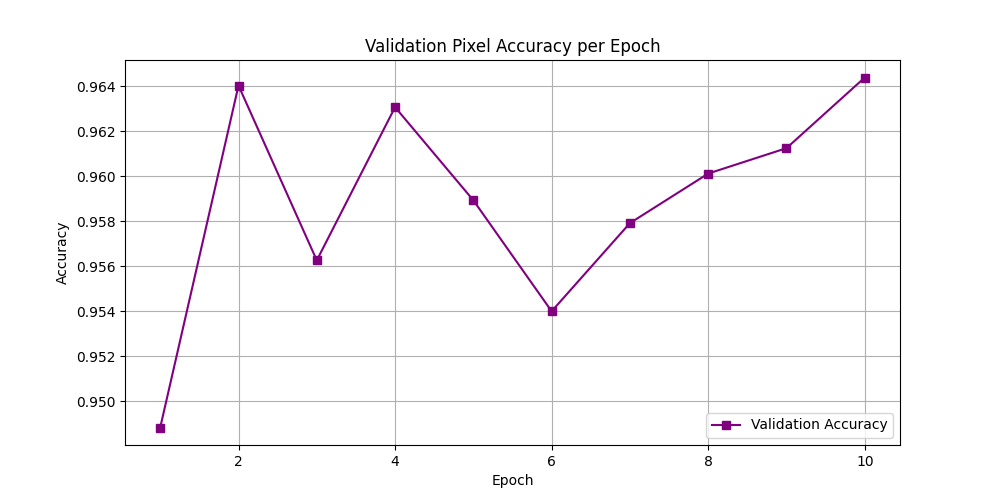

In [ ]:
from IPython.display import Image
Image('validation_accuracy.png')

In [ ]:
model.eval()

iou_total = 0
dice_total = 0

with torch.no_grad():

    for images,masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        iou_total += iou_score(
            outputs,
            masks
        )

        dice_total += dice_score(
            outputs,
            masks
        )

print(
    "IoU:",
    iou_total/len(val_loader)
)

print(
    "Dice:",
    dice_total/len(val_loader)
)

IoU: tensor(0.7308, device='cuda:0')
Dice: tensor(0.8402, device='cuda:0')


## Test Set Evaluation

In [ ]:
from torch.utils.data import DataLoader
import torchmetrics

# Load the test dataset
test_dataset = FruitSegDataset(
    TEST_IMAGES_DIR,
    TEST_ANNOTATIONS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False # No need to shuffle test data
)

print(f"Test dataset loaded with {len(test_dataset)} images.")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Test dataset loaded with 45 images.


In [ ]:
from tqdm import tqdm

model.eval()

current_test_loss = 0
current_test_iou = 0
current_test_dice = 0
current_test_accuracy = 0

# Initialize torchmetrics for test set
binary_precision_test = torchmetrics.classification.BinaryPrecision().to(device)
binary_recall_test = torchmetrics.classification.BinaryRecall().to(device)

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Set Evaluation", unit="batch"):
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        masks = masks.float() # Ensure masks are float for loss calculation
        loss = loss_fn(outputs, masks)
        current_test_loss += loss.item()

        # Calculate IoU, Dice, and Pixel Accuracy for the batch
        current_test_iou += iou_score(outputs, masks).item()
        current_test_dice += dice_score(outputs, masks).item()
        current_test_accuracy += pixel_accuracy(outputs, masks).item()

        # For precision and recall, apply sigmoid and threshold
        preds_binary = (torch.sigmoid(outputs) > 0.5).int()
        binary_precision_test.update(preds_binary, masks.int())
        binary_recall_test.update(preds_binary, masks.int())

avg_test_loss = current_test_loss / len(test_loader)
avg_test_iou = current_test_iou / len(test_loader)
avg_test_dice = current_test_dice / len(test_loader)
avg_test_accuracy = current_test_accuracy / len(test_loader)

avg_test_precision = binary_precision_test.compute().item()
avg_test_recall = binary_recall_test.compute().item()

print(f"\nTest Loss: {avg_test_loss:.4f}")
print(f"Test IoU: {avg_test_iou:.4f}")
print(f"Test Dice Score: {avg_test_dice:.4f}")
print(f"Test Precision: {avg_test_precision:.4f}")
print(f"Test Recall: {avg_test_recall:.4f}")
print(f"Test Accuracy: {avg_test_accuracy:.4f}")

Test Set Evaluation: 100%|██████████| 6/6 [00:00<00:00, 10.40batch/s]


Test Loss: 0.3070
Test IoU: 0.7610
Test Dice Score: 0.8589
Test Precision: 0.8808
Test Recall: 0.8339
Test Accuracy: 0.9636


In [ ]:
import time

model.eval()
num_inference_images_test = len(test_dataset) # Use all test images for inference time calculation
total_inference_time_test = 0

with torch.no_grad():
    for i in tqdm(range(num_inference_images_test), desc="Calculating Test Inference Time", unit="image"):
        image, _ = test_dataset[i]
        image = image.unsqueeze(0).to(device) # Add batch dimension and move to device

        start_time = time.time()
        _ = model(image)
        end_time = time.time()

        total_inference_time_test += (end_time - start_time)

avg_inference_time_test = total_inference_time_test / num_inference_images_test
fps_test = 1 / avg_inference_time_test

print(f"\nAverage Inference Time per image on Test Set: {avg_inference_time_test:.4f} seconds")
print(f"Frames Per Second (FPS) on Test Set: {fps_test:.2f}")

Calculating Test Inference Time: 100%|██████████| 45/45 [00:00<00:00, 82.09image/s]


Average Inference Time per image on Test Set: 0.0074 seconds
Frames Per Second (FPS) on Test Set: 135.88


### Inference on a new image

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import torch
import skimage.measure # Added for connected component labeling
import skimage.morphology # Added for potential morphological operations, if needed

# Load the new sample image
sample_image_path_new = SAMPLE_IMAGE_PATH
sample_image_new = cv2.imread(sample_image_path_new)
sample_image_new = cv2.cvtColor(sample_image_new, cv2.COLOR_BGR2RGB)

# Preprocess the image to match model input (256x256, normalized, permuted)
preprocessed_image_new = cv2.resize(sample_image_new, (256, 256))
preprocessed_image_new = preprocessed_image_new / 255.0
input_tensor_new = torch.tensor(preprocessed_image_new, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)

# Move input to the correct device
input_tensor_new = input_tensor_new.to(device)

model.eval()

with torch.no_grad():
    pred_new = model(input_tensor_new)

pred_new = torch.sigmoid(pred_new)[0][0]
pred_new = pred_new.cpu().numpy()

# Define a list of thresholds to test for damaged pixels
fruit_detection_threshold = 0.07 # Increased threshold to more accurately detect individual fruits
damage_thresholds = [0.99] # Various thresholds for highly confident damaged pixels

# Create a binary mask of all fruit-like regions in the image based on fruit_detection_threshold
combined_fruit_mask_binary = (pred_new > fruit_detection_threshold).astype(np.uint8)

# Apply morphological closing to fill small holes and connect nearby components
# This helps in getting a more complete fruit mask before labeling
structuring_element = skimage.morphology.disk(5) # Reduced the size of the disk to prevent merging distinct fruits
combined_fruit_mask_closed = skimage.morphology.binary_closing(combined_fruit_mask_binary, structuring_element)

# Remove small objects (noise) from the closed mask before labeling
# This helps in filtering out isolated pixels or very small disconnected components
min_object_size = 10 # Slightly reduced minimum size to avoid discarding smaller fruit segments
cleaned_fruit_mask = skimage.morphology.remove_small_objects(combined_fruit_mask_closed.astype(bool), min_size=min_object_size)

# Use connected component labeling to find individual fruit instances
# Each connected component will have a unique integer label
labels = skimage.measure.label(cleaned_fruit_mask) # Use the cleaned mask for labeling
num_fruits = labels.max() # Get the number of unique fruit instances detected

print(f"Total fruit pixels detected (threshold > {fruit_detection_threshold}): {np.sum(combined_fruit_mask_binary)}")
print(f"Detected {num_fruits} individual fruit instances.")

if num_fruits == 0:
    print("No fruit instances detected at the given fruit_detection_threshold.")
else:
    # Define a minimum size for a fruit instance to be considered valid
    # After removing small objects, setting this to 1 is fine as noise should already be gone
    min_fruit_pixels = 1

    total_damage_percentage_sum = 0.0
    valid_fruit_instance_count = 0

    for i in range(1, num_fruits + 1): # Iterate through each unique label (fruit instance)
        fruit_instance_mask = (labels == i) # Binary mask for the current fruit instance

        # Calculate total pixels for this specific fruit instance
        total_fruit_pixels_instance = np.sum(fruit_instance_mask)

        # Filter out very small fruit instances that might be noise or tiny defects
        if total_fruit_pixels_instance < min_fruit_pixels:
            print(f"Fruit instance {i} has only {total_fruit_pixels_instance} pixels, which is less than the minimum of {min_fruit_pixels}. Skipping.")
            continue

        # Calculate bounding box for the current fruit instance
        # Find coordinates of true pixels in the fruit_instance_mask
        coords = np.argwhere(fruit_instance_mask)
        if coords.size > 0:
            y_min, x_min = coords.min(axis=0)
            y_max, x_max = coords.max(axis=0)
        else:
            y_min, x_min, y_max, x_max = 0, 0, 0, 0 # Default if no pixels


        print(f"\n--- Processing Fruit Instance {i} ---")
        print(f"Total pixels for Fruit {i}: {total_fruit_pixels_instance}")

        if total_fruit_pixels_instance == 0:
            print(f"Fruit instance {i} has 0 pixels, skipping damage calculation.")
            continue

        for damage_thresh in damage_thresholds:
            # Calculate damaged pixels *only within the current fruit instance's mask*
            # Apply damage_thresh to the original prediction map, then intersect with fruit_instance_mask
            damaged_pixels_instance = np.sum((pred_new > damage_thresh) & fruit_instance_mask)
            if total_fruit_pixels_instance > 0:
                damage_percentage_instance = (damaged_pixels_instance / total_fruit_pixels_instance) * 100
            else:
                damage_percentage_instance = 0.0 # Should not happen if total_fruit_pixels_instance > 0 check passes
            total_damage_percentage_sum += damage_percentage_instance
            valid_fruit_instance_count += 1
            plt.figure(figsize=(15, 5))
            plt.subplot(1, 3, 1) # First subplot for the original image
            plt.imshow(preprocessed_image_new)
            if coords.size > 0: # Draw bounding box if fruit pixels exist
                rect = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                     linewidth=3, edgecolor='cyan', facecolor='none') # Increased linewidth
                plt.gca().add_patch(rect)
                plt.text(x_min, y_min - 5, f'Fruit {i}', color='cyan', fontsize=10, weight='bold',
                                     bbox=dict(facecolor='black', alpha=0.5))
            plt.title("Original Image with Fruit Bounding Box")
            plt.axis('off')
            plt.subplot(1, 3, 2) # Second subplot for the overlay
            plt.imshow(preprocessed_image_new)
            # Highlight the current fruit instance with a distinct color (green for overall fruit)
            plt.imshow(fruit_instance_mask, alpha=0.4, cmap='Greens') # Show current fruit instance in green
            # Highlight the current fruit instance with a distinct color (blue for original 'fruit mask')
            plt.imshow(fruit_instance_mask, alpha=0.2, cmap='Blues') # Show current fruit instance (original blue)
            # Highlight damage on top in red
            plt.imshow((pred_new > damage_thresh) & fruit_instance_mask, alpha=0.5, cmap='Reds') # Show damage with red
            plt.title(f"Fruit {i} Overlay (Damage Thresh: {damage_thresh:.3f})")
            plt.axis('off')
            # Add damage percentage text to the overlay image
            plt.text(10, 240, f"Damage: {damage_percentage_instance:.2f}%", color='white', fontsize=12,
                                 bbox=dict(facecolor='black', alpha=0.5))
            plt.subplot(1, 3, 3) # Third subplot for the damage mask
            plt.imshow((pred_new > damage_thresh) & fruit_instance_mask, cmap='gray')
            plt.title(f"Fruit {i} Damage Mask (Threshold: {damage_thresh:.3f})")
            plt.axis('off')
            plt.show()
    if valid_fruit_instance_count > 0:
        average_damage_percentage = total_damage_percentage_sum / valid_fruit_instance_count
        print(f"\nOverall Average Damage Percentage across valid fruit instances: {average_damage_percentage:.2f}%")
    else:
        print("No valid fruit instances were found to calculate an average damage percentage.")

Visualizing Raw Model Output

This visualization shows the raw confidence map from the model ( pred_new ) before any thresholding or morphological operations.
This helps us understand what the model itself is primarily detecting across the image.

In [ ]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(preprocessed_image_new)
plt.title("Original Image")
plt.axis('off')
plt.subplot(1, 2, 2)
# Visualize the raw prediction map without any thresholding
plt.imshow(pred_new, cmap='viridis') # Using viridis or 'hot' or 'jet' to show intensity
plt.colorbar(label='Confidence')
plt.title("Raw Model Prediction (pred_new) Heatmap")
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import os

# Create a directory to save the model if it doesn't exist
model_save_dir = MODEL_SAVE_DIR
os.makedirs(model_save_dir, exist_ok=True)

# Save the entire model (including architecture, parameters, and optimizer state)
# It's good practice to save the optimizer state as well if you plan to resume training
checkpoint_path = os.path.join(model_save_dir, 'fruit_segmentation_model.pth')
torch.save({
    'epoch': epochs,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'train_losses': train_losses,
    'val_losses': val_losses,
    'val_ious': val_ious,
    'val_dices': val_dices,
    'val_precisions': val_precisions,
    'val_recalls': val_recalls,
    'val_accuracies': val_accuracies,
    }, checkpoint_path)

print(f"Model saved to {checkpoint_path}")